In [96]:
import numpy as np
import pandas as pd
import difflib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


In [97]:
movies_data= pd.read_csv("/content/movies.csv")
movies_data.head()

,index,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew,director
0,0,237000000,Action Adventure Fantasy Science Fiction,http://www.avatarmovie.com/,19995,culture clash future space war space colony so...,en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Sam Worthington Zoe Saldana Sigourney Weaver S...,"[{'name': 'Stephen E. Rivkin', 'gender': 0, 'd...",James Cameron
1,1,300000000,Adventure Fantasy Action,http://disney.go.com/disneypictures/pirates/,285,ocean drug abuse exotic island east india trad...,en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Johnny Depp Orlando Bloom Keira Knightley Stel...,"[{'name': 'Dariusz Wolski', 'gender': 2, 'depa...",Gore Verbinski
2,2,245000000,Action Adventure Crime,http://www.sonypictures.com/movies/spectre/,206647,spy based on novel secret agent sequel mi6,en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Daniel Craig Christoph Waltz L\u00e9a Seydoux ...,"[{'name': 'Thomas Newman', 'gender': 2, 'depar...",Sam Mendes
3,3,250000000,Action Crime Drama Thriller,http://www.thedarkknightrises.com/,49026,dc comics crime fighter terrorist secret ident...,en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,Christian Bale Michael Caine Gary Oldman Anne ...,"[{'name': 'Hans Zimmer', 'gender': 2, 'departm...",Christopher Nolan
4,4,260000000,Action Adventure Science Fiction,http://movies.disney.com/john-carter,49529,based on novel mars medallion space travel pri...,en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,Taylor Kitsch Lynn Collins Samantha Morton Wil...,"[{'name': 'Andrew Stanton', 'gender': 2, 'depa...",Andrew Stanton


In [98]:
movies_data.shape

(4803, 24)

In [99]:
movies_data.isna().sum().sort_values(ascending=False)

,0
homepage,3091
tagline,844
keywords,412
cast,43
director,30
genres,28
overview,3
runtime,2
release_date,1
original_title,0


In [100]:
movies_data.columns

Index(['index', 'budget', 'genres', 'homepage', 'id', 'keywords',
       'original_language', 'original_title', 'overview', 'popularity',
       'production_companies', 'production_countries', 'release_date',
       'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title',
       'vote_average', 'vote_count', 'cast', 'crew', 'director'],
      dtype='object')

In [101]:
selected_feature=['genres', 'keywords','tagline', 'cast' ,'director']

In [102]:
selected_data=movies_data[selected_feature]
selected_data

,genres,keywords,tagline,cast,director
0,Action Adventure Fantasy Science Fiction,culture clash future space war space colony so...,Enter the World of Pandora.,Sam Worthington Zoe Saldana Sigourney Weaver S...,James Cameron
1,Adventure Fantasy Action,ocean drug abuse exotic island east india trad...,"At the end of the world, the adventure begins.",Johnny Depp Orlando Bloom Keira Knightley Stel...,Gore Verbinski
2,Action Adventure Crime,spy based on novel secret agent sequel mi6,A Plan No One Escapes,Daniel Craig Christoph Waltz L\u00e9a Seydoux ...,Sam Mendes
3,Action Crime Drama Thriller,dc comics crime fighter terrorist secret ident...,The Legend Ends,Christian Bale Michael Caine Gary Oldman Anne ...,Christopher Nolan
4,Action Adventure Science Fiction,based on novel mars medallion space travel pri...,"Lost in our world, found in another.",Taylor Kitsch Lynn Collins Samantha Morton Wil...,Andrew Stanton
...,...,...,...,...,...
4798,Action Crime Thriller,united states\u2013mexico barrier legs arms pa...,"He didn't come looking for trouble, but troubl...",Carlos Gallardo Jaime de Hoyos Peter Marquardt...,Robert Rodriguez
4799,Comedy Romance,NaN,A newlywed couple's honeymoon is upended by th...,Edward Burns Kerry Bish\u00e9 Marsha Dietlein ...,Edward Burns
4800,Comedy Drama Romance TV Movie,date love at first sight narration investigati...,NaN,Eric Mabius Kristin Booth Crystal Lowe Geoff G...,Scott Smith
4801,NaN,NaN,A New Yorker in Shanghai,Daniel Henney Eliza Coupe Bill Paxton Alan Ruc...,Daniel Hsia


In [103]:
selected_data.isna().sum().sort_values(ascending=False)

,0
tagline,844
keywords,412
cast,43
director,30
genres,28


In [104]:
for feature in selected_feature:
  movies_data[feature]=movies_data[feature].fillna("")

In [105]:
movies_data.isna().sum().sort_values(ascending=False)

,0
homepage,3091
overview,3
runtime,2
release_date,1
id,0
index,0
budget,0
genres,0
original_title,0
original_language,0


In [106]:
selected_feature

['genres', 'keywords', 'tagline', 'cast', 'director']

In [107]:
combined_features=movies_data["genres"]+" "+movies_data["keywords"]+" "+movies_data["tagline"]+" "+movies_data["cast"]+" "+movies_data['director']

In [108]:
combined_features

,0
0,Action Adventure Fantasy Science Fiction cultu...
1,Adventure Fantasy Action ocean drug abuse exot...
2,Action Adventure Crime spy based on novel secr...
3,Action Crime Drama Thriller dc comics crime fi...
4,Action Adventure Science Fiction based on nove...
...,...
4798,Action Crime Thriller united states\u2013mexic...
4799,Comedy Romance A newlywed couple's honeymoon ...
4800,Comedy Drama Romance TV Movie date love at fir...
4801,A New Yorker in Shanghai Daniel Henney Eliza...


#convert text data to feature vector

In [109]:
vectorizer=TfidfVectorizer()
feature_vectors=vectorizer.fit_transform(combined_features)

In [110]:
print(feature_vectors)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 124266 stored elements and shape (4803, 17318)>
  Coords	Values
  (0, 201)	0.07860022416510505
  (0, 274)	0.09021200873707368
  (0, 5274)	0.11108562744414445
  (0, 13599)	0.1036413987316636
  (0, 5437)	0.1036413987316636
  (0, 3678)	0.21392179219912877
  (0, 3065)	0.22208377802661425
  (0, 5836)	0.1646750903586285
  (0, 14378)	0.33962752210959823
  (0, 16587)	0.12549432354918996
  (0, 3225)	0.24960162956997736
  (0, 14271)	0.21392179219912877
  (0, 4945)	0.24025852494110758
  (0, 15261)	0.07095833561276566
  (0, 16998)	0.1282126322850579
  (0, 11192)	0.09049319826481456
  (0, 11503)	0.27211310056983656
  (0, 13349)	0.15021264094167086
  (0, 17007)	0.23643326319898797
  (0, 17290)	0.20197912553916567
  (0, 13319)	0.2177470539412484
  (0, 14064)	0.20596090415084142
  (0, 16668)	0.19843263965100372
  (0, 14608)	0.15150672398763912
  (0, 8756)	0.22709015857011816
  :	:
  (4801, 403)	0.17727585190343229
  (4801, 4835)	0.247137650

In [111]:
feature_names = vectorizer.get_feature_names_out()

print(feature_names[275])

adventurer


In [112]:
row = feature_vectors[3]

for index, value in zip(row.indices, row.data):
    print(feature_names[index], value)

action 0.08776275872337966
the 0.07923004487511981
crime 0.20987593650816166
secret 0.1637046597397786
drama 0.06289356380696848
thriller 0.08476657998789669
dc 0.2299700456256995
comics 0.22842670218675082
fighter 0.21914576533671676
terrorist 0.21799445920041566
identity 0.18858761786188202
burglar 0.2731080483956869
legend 0.20813330041521613
ends 0.24313012285601762
christian 0.1800950402626618
bale 0.22842670218675082
michael 0.1157230169157549
caine 0.2299700456256995
gary 0.17815537487554683
oldman 0.22552410568979847
anne 0.18431644017895038
hathaway 0.22552410568979847
tom 0.14600123962135028
hardy 0.24797238474008493
christopher 0.15940531654296083
nolan 0.2535623658423528


##getting similarity score using cosine similarity

In [113]:
similarity=cosine_similarity(feature_vectors)
print(similarity)

[[1.         0.07219487 0.037733   ... 0.         0.         0.        ]
 [0.07219487 1.         0.03281499 ... 0.03575545 0.         0.        ]
 [0.037733   0.03281499 1.         ... 0.         0.05389661 0.        ]
 ...
 [0.         0.03575545 0.         ... 1.         0.         0.02651502]
 [0.         0.         0.05389661 ... 0.         1.         0.        ]
 [0.         0.         0.         ... 0.02651502 0.         1.        ]]


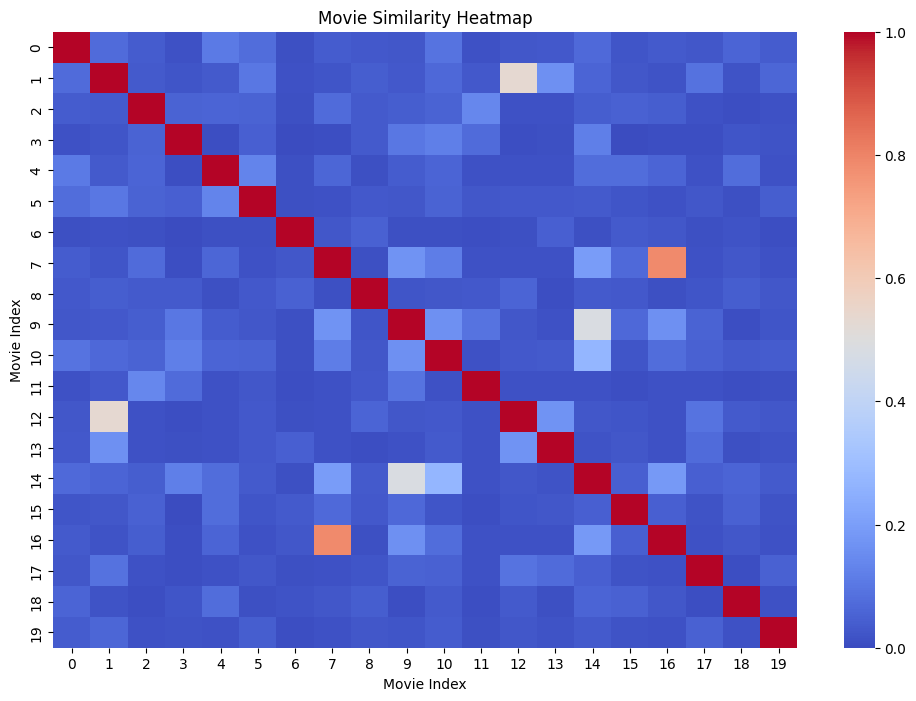

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    similarity[:20, :20],
    cmap="coolwarm",
)

plt.title("Movie Similarity Heatmap")
plt.xlabel("Movie Index")
plt.ylabel("Movie Index")
plt.show()

In [115]:
similarity.shape

(4803, 4803)

In [148]:
movie_name=input("Enter your favourite movie: ")

Enter your favourite movie: Brigham City


In [149]:
list_of_all_title=movies_data["title"].tolist()
print(list_of_all_title)

['Avatar', "Pirates of the Caribbean: At World's End", 'Spectre', 'The Dark Knight Rises', 'John Carter', 'Spider-Man 3', 'Tangled', 'Avengers: Age of Ultron', 'Harry Potter and the Half-Blood Prince', 'Batman v Superman: Dawn of Justice', 'Superman Returns', 'Quantum of Solace', "Pirates of the Caribbean: Dead Man's Chest", 'The Lone Ranger', 'Man of Steel', 'The Chronicles of Narnia: Prince Caspian', 'The Avengers', 'Pirates of the Caribbean: On Stranger Tides', 'Men in Black 3', 'The Hobbit: The Battle of the Five Armies', 'The Amazing Spider-Man', 'Robin Hood', 'The Hobbit: The Desolation of Smaug', 'The Golden Compass', 'King Kong', 'Titanic', 'Captain America: Civil War', 'Battleship', 'Jurassic World', 'Skyfall', 'Spider-Man 2', 'Iron Man 3', 'Alice in Wonderland', 'X-Men: The Last Stand', 'Monsters University', 'Transformers: Revenge of the Fallen', 'Transformers: Age of Extinction', 'Oz: The Great and Powerful', 'The Amazing Spider-Man 2', 'TRON: Legacy', 'Cars 2', 'Green Lant

In [150]:
find_close_match=difflib.get_close_matches(movie_name,list_of_all_title)
find_close_match

['Brigham City', 'Broken City', 'Sin City']

In [151]:
close_match=find_close_match[0]
close_match

'Brigham City'

In [152]:
#find the index of the movie with title
index_of_the_movie=movies_data[movies_data.title==close_match]["index"].values[0]
print(index_of_the_movie)

4370


In [153]:
#getting a list of similar movie
similarity_score=list(enumerate(similarity[index_of_the_movie]))
print(similarity_score)

[(0, np.float64(0.0)), (1, np.float64(0.0)), (2, np.float64(0.011487550873905076)), (3, np.float64(0.03775702147539946)), (4, np.float64(0.0)), (5, np.float64(0.0)), (6, np.float64(0.0)), (7, np.float64(0.0)), (8, np.float64(0.0)), (9, np.float64(0.0)), (10, np.float64(0.0)), (11, np.float64(0.016482501824314794)), (12, np.float64(0.0)), (13, np.float64(0.0)), (14, np.float64(0.0)), (15, np.float64(0.0)), (16, np.float64(0.0)), (17, np.float64(0.0)), (18, np.float64(0.0)), (19, np.float64(0.03737782663658677)), (20, np.float64(0.0)), (21, np.float64(0.0)), (22, np.float64(0.038927939763545576)), (23, np.float64(0.0)), (24, np.float64(0.003804892507971148)), (25, np.float64(0.011437069330870839)), (26, np.float64(0.0)), (27, np.float64(0.006673845867304126)), (28, np.float64(0.007327095183750945)), (29, np.float64(0.007665232574713415)), (30, np.float64(0.0)), (31, np.float64(0.0)), (32, np.float64(0.0)), (33, np.float64(0.007348948623014242)), (34, np.float64(0.0)), (35, np.float64(0.0

In [154]:
#sorting moives based on thier similarity score
sorted_similar_movies=sorted(similarity_score,key=lambda x:x[1],reverse=True)
print(sorted_similar_movies)


[(4370, np.float64(1.0000000000000002)), (1318, np.float64(0.22556260108541043)), (2062, np.float64(0.15324786898482412)), (3616, np.float64(0.13766416663111042)), (3391, np.float64(0.1304783174743261)), (4779, np.float64(0.11930544987183356)), (4502, np.float64(0.1189418912626501)), (2252, np.float64(0.09956230768532635)), (4714, np.float64(0.0977082773266878)), (3831, np.float64(0.09453613034541086)), (1282, np.float64(0.08890133241019053)), (1765, np.float64(0.08830567297551534)), (4692, np.float64(0.08827015128984692)), (3564, np.float64(0.08365490693966143)), (3978, np.float64(0.08221224698373258)), (4691, np.float64(0.08128181082682437)), (3470, np.float64(0.08017819688333111)), (2686, np.float64(0.07981835535001634)), (1457, np.float64(0.07900552778405626)), (4184, np.float64(0.07691102661048449)), (1503, np.float64(0.07676904444063114)), (1417, np.float64(0.07376858726840378)), (663, np.float64(0.07107184736015439)), (1129, np.float64(0.07063905033653846)), (4680, np.float64(0.

In [155]:
#print the name of similar movie based on the index

print("Movies Suggested for you :")

i=1

for movie in sorted_similar_movies:
  index=movie[0]
  title_from_index=movies_data[movies_data.index==index]["title"].values[0]
  if i<21:
    print(i," .",title_from_index)
    i+=1



Movies Suggested for you :
1  . Brigham City
2  . The Thing
3  . My Fellow Americans
4  . Robin and Marian
5  . Dom Hemingway
6  . Slacker
7  . Water & Power
8  . Marci X
9  . An American in Hollywood
10  . In Cold Blood
11  . The Hunting Party
12  . The Newton Boys
13  . Theresa Is a Mother
14  . The Robe
15  . Amnesiac
16  . Yesterday Was a Lie
17  . Bernie
18  . An American Haunting
19  . Smilla's Sense of Snow
20  . Deadline - U.S.A.


In [156]:
# first_10_movie=sorted_similar_movies[:11]
# first_10_movie

[(4370, np.float64(1.0000000000000002)),
 (1318, np.float64(0.22556260108541043)),
 (2062, np.float64(0.15324786898482412)),
 (3616, np.float64(0.13766416663111042)),
 (3391, np.float64(0.1304783174743261)),
 (4779, np.float64(0.11930544987183356)),
 (4502, np.float64(0.1189418912626501)),
 (2252, np.float64(0.09956230768532635)),
 (4714, np.float64(0.0977082773266878)),
 (3831, np.float64(0.09453613034541086)),
 (1282, np.float64(0.08890133241019053))]

In [157]:
# for movie_index, score in first_10_movie[1:11]:
#     print(movies_data.iloc[movie_index]["title"])

The Thing
My Fellow Americans
Robin and Marian
Dom Hemingway
Slacker
Water & Power
Marci X
An American in Hollywood
In Cold Blood
The Hunting Party


###Movie Recommendation System

In [169]:
movie_name=input("Enter your favourite movie: ")

list_of_all_title=movies_data["title"].tolist()

find_close_match=difflib.get_close_matches(movie_name,list_of_all_title)

close_match=find_close_match[0]

index_of_the_movie=movies_data[movies_data.title==close_match]["index"].values[0]

similarity_score=list(enumerate(similarity[index_of_the_movie]))

sorted_similar_movies=sorted(similarity_score,key=lambda x:x[1],reverse=True)

#print the name of similar movie based on the index

print("\nMovies Suggested for you :\n")

i=1

for movie in sorted_similar_movies[1:21]:
  index=movie[0]
  title_from_index=movies_data[movies_data.index==index]["title"].values[0]
  print(i," .",title_from_index)
  i+=1



Enter your favourite movie: batt mann

Movies Suggested for you :

1  . Batman Returns
2  . Batman & Robin
3  . The Dark Knight Rises
4  . Batman Begins
5  . The Dark Knight
6  . A History of Violence
7  . Superman
8  . Beetlejuice
9  . Bedazzled
10  . Mars Attacks!
11  . The Sentinel
12  . Planet of the Apes
13  . Man of Steel
14  . Suicide Squad
15  . The Mask
16  . Salton Sea
17  . Spider-Man 3
18  . The Postman Always Rings Twice
19  . Hang 'em High
20  . Spider-Man 2
